<a href="https://colab.research.google.com/github/dananatsheh891-netizen/DANA-NATSHEH-HW-1-.-/blob/main/EDA_Dana.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
###Load packages
# I installed this library to create graphs and visualize the data.
%pip install matplotlib

# I installed this library to read and analyze the dataset.
%pip install pandas

# I installed this library to create statistical graphs.
%pip install seaborn

# I installed this library to use data preprocessing tools.
%pip install scikit-learn






In [ ]:
# I imported pandas to read and analyze the dataset.
import pandas as pd

# I imported numpy to work with numerical data.
import numpy as np

# I imported matplotlib to create graphs.
import matplotlib.pyplot as plt

# I imported seaborn to create statistical visualizations.
import seaborn as sns

# I imported tools for data preprocessing and feature selection.
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

print("All packages loaded successfully.")

All packages loaded successfully.


## Step 2.2 — Load the dataset

In [ ]:
# # I set the path to the uploaded dataset in Colab.
DATA_PATH = "/content/german_credit_data.csv"
# I loaded the dataset into a table so I can explore and analyze it.
dataset = pd.read_csv(DATA_PATH)

# I checked the number of rows and columns to understand the dataset size.
print(f"Dataset loaded: {dataset.shape[0]} rows, {dataset.shape[1]} columns")

Dataset loaded: 1000 rows, 10 columns


## Step 3 — Exploratory Data Analysis (EDA)

In [ ]:
# I displayed the first few rows to get a quick look at the dataset.
dataset.head()

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


In [ ]:
# I displayed the first few rows to get a quick look at the dataset.
dataset.head()

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


In [ ]:
# I checked the number of rows and columns to understand the dataset size.
print("Shape (rows, columns):", dataset.shape)

Shape (rows, columns): (1000, 10)


In [ ]:
# I checked the data type of each column to understand how the data is stored.
dataset.dtypes

,0
Age,int64
Sex,object
Job,int64
Housing,object
SavingAccounts,object
CheckingAccount,object
CreditAmount,int64
Duration,int64
Purpose,object
Risk,object


In [ ]:
# I summarized the numerical columns to understand their values and detect unusual numbers.
dataset.describe()

,Age,Job,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


In [ ]:
# I summarized the categorical columns to understand their categories and most common values.
dataset.describe(exclude="number")

,Sex,Housing,SavingAccounts,CheckingAccount,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


In [ ]:
# I checked how many missing values exist in each column.
missing_counts = dataset.isna().sum()

# I displayed the number of missing values for each column.
print("Missing values per column:\n")
print(missing_counts)

Missing values per column:

Age                  0
Sex                  0
Job                  0
Housing              0
SavingAccounts     183
CheckingAccount    394
CreditAmount         0
Duration             0
Purpose              0
Risk                 0
dtype: int64


In [ ]:
# I counted how many good and bad credit risk cases are in the dataset.
print(dataset["Risk"].value_counts())

# I calculated the percentage of each risk category to understand the data balance.
print(dataset["Risk"].value_counts(normalize=True).round(3) * 100, "% of total")

Risk
good    700
bad     300
Name: count, dtype: int64
Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64 % of total


### Figure — missing values by column

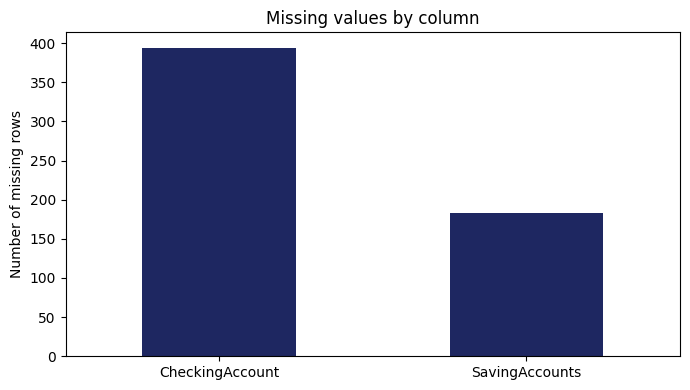

In [ ]:
# I counted the missing values in each column.
missing_counts = dataset.isna().sum()

# I kept only the columns that have missing values and sorted them from highest to lowest.
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

# I set the size of the graph.
plt.figure(figsize=(7, 4))

# I created a bar chart to show the number of missing values in each column.
missing_counts.plot(kind="bar", color="#1E2761")

# I added a title and a label to explain the graph.
plt.title("Missing values by column")
plt.ylabel("Number of missing rows")

# I kept the column names horizontal to make them easier to read.
plt.xticks(rotation=0)

# I adjusted the graph layout to make everything fit clearly.
plt.tight_layout()

# I displayed the graph.
plt.show()

# I found that SavingAccounts and CheckingAccount have missing values.
# These missing values may mean that some applicants do not have these accounts.
# I will handle these values during data cleaning instead of deleting the rows.

### 3.2 Data visualization

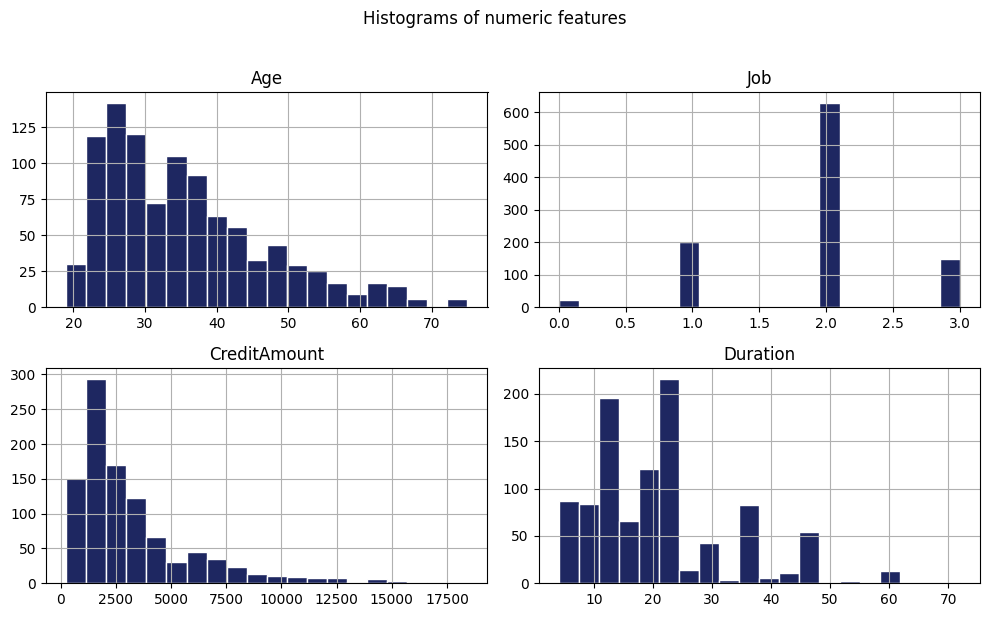

In [ ]:
# I selected the numerical columns I want to explore.
numeric_cols = ["Age", "Job", "CreditAmount", "Duration"]

# I created histograms to see how the numerical values are distributed.
dataset[numeric_cols].hist(figsize=(10, 6), bins=20, color="#1E2761", edgecolor="white")

# I added a title for all the histograms.
plt.suptitle("Histograms of numeric features", y=1.02)

# I adjusted the layout to make the graphs fit clearly.
plt.tight_layout()

# I displayed the histograms.
plt.show()

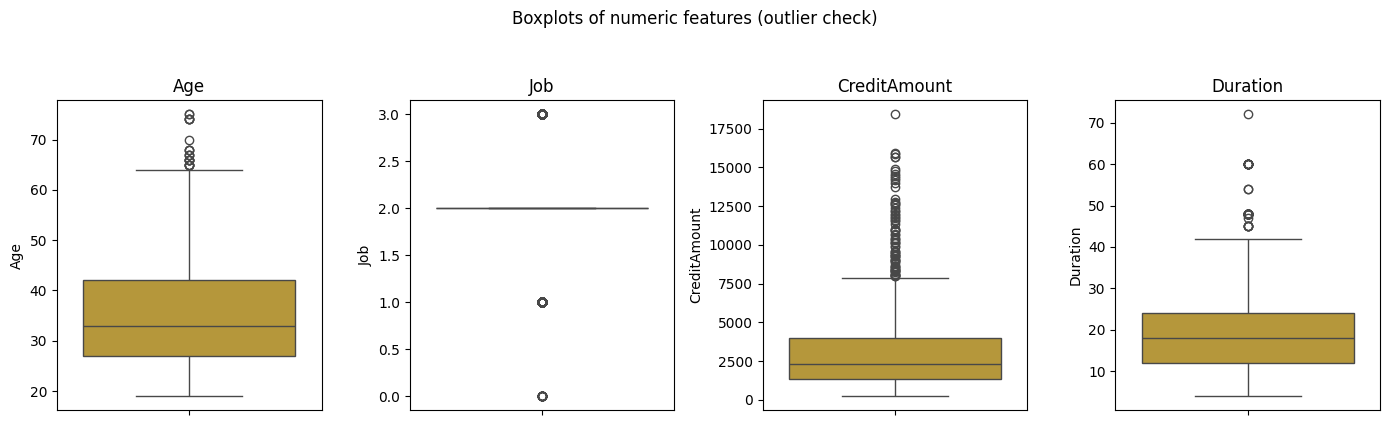

In [ ]:
# I created a separate plot for each numerical column.
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(14, 4))

# I created a boxplot for each column to check for unusual values.
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=dataset[col], ax=ax, color="#C9A227")
    ax.set_title(col)

# I added a main title for all the boxplots.
plt.suptitle("Boxplots of numeric features (outlier check)", y=1.05)

# I adjusted the layout to make the plots fit clearly.
plt.tight_layout()

# I displayed the boxplots.
plt.show()

# I observed that CreditAmount and Duration have some unusually high values.
# These values may represent large credit amounts or long credit durations.


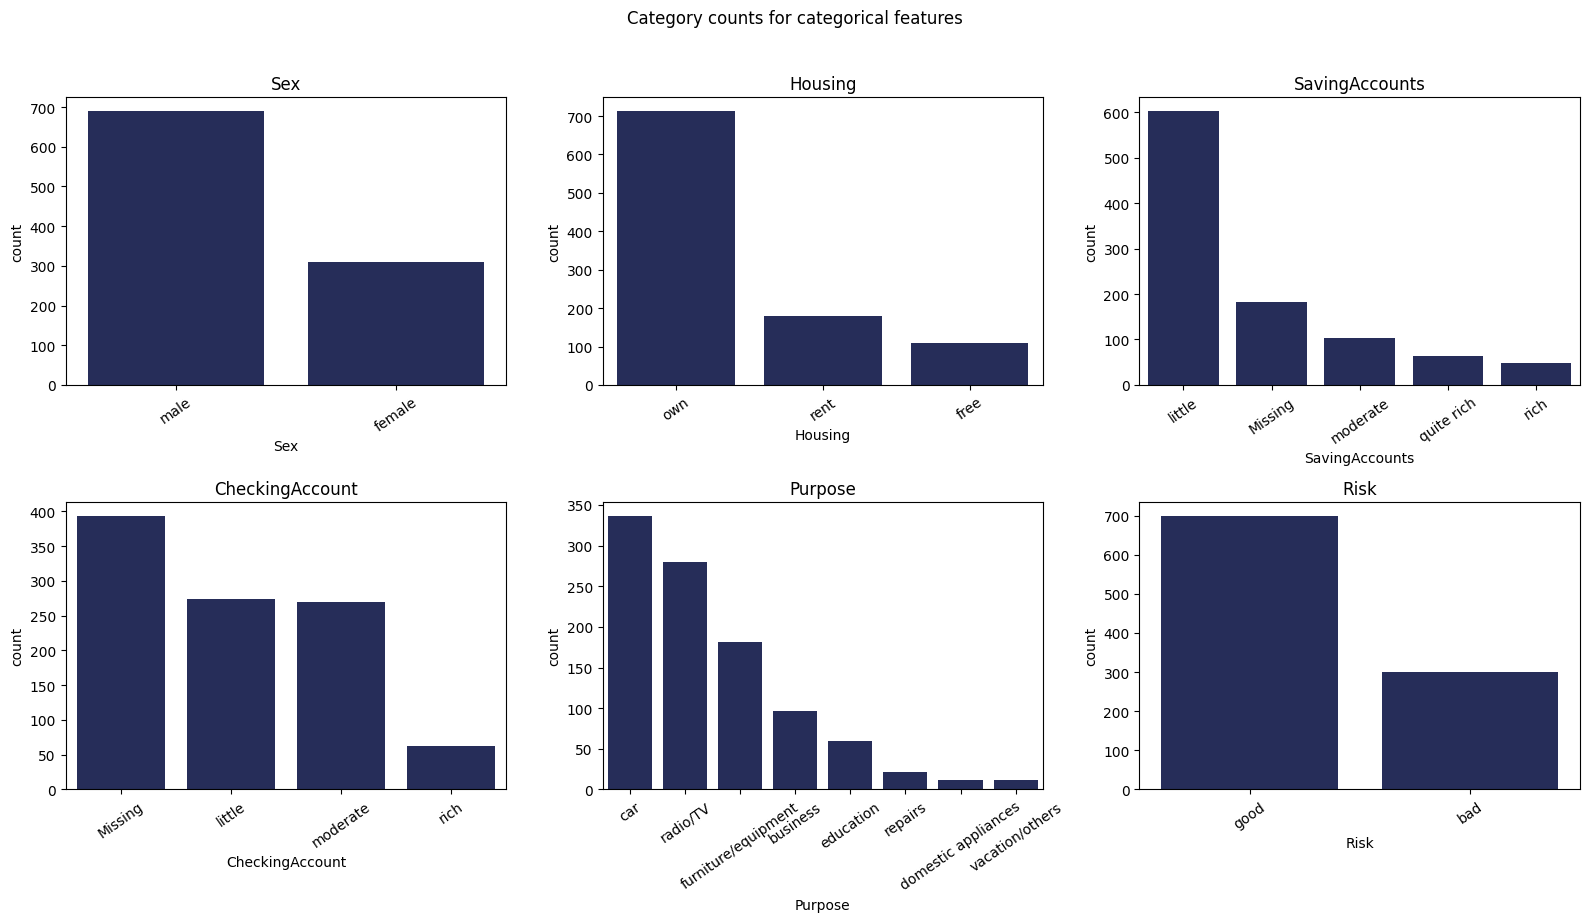

In [ ]:
# I selected the categorical columns I want to explore.
categorical_cols = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

# I created six plots arranged in two rows and three columns.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# I arranged the plots in a single list to make them easier to use in the loop.
axes = axes.flatten()

# I created a count plot for each categorical column.
for ax, col in zip(axes, categorical_cols):
    # I replaced missing values with "Missing" so they appear in the chart.
    col_data = dataset[col].fillna("Missing")

    # I sorted the categories from most common to least common.
    order = col_data.value_counts().index

    # I created a bar chart showing the count of each category.
    sns.countplot(x=col_data, order=order, ax=ax, color="#1E2761")

    # I added the column name as the plot title.
    ax.set_title(col)

    # I rotated the category labels to make them easier to read.
    ax.tick_params(axis="x", rotation=35)

# I added a main title for all the plots.
plt.suptitle("Category counts for categorical features", y=1.02)

# I adjusted the layout to make the plots fit clearly.
plt.tight_layout()

# I displayed all the plots.
plt.show()


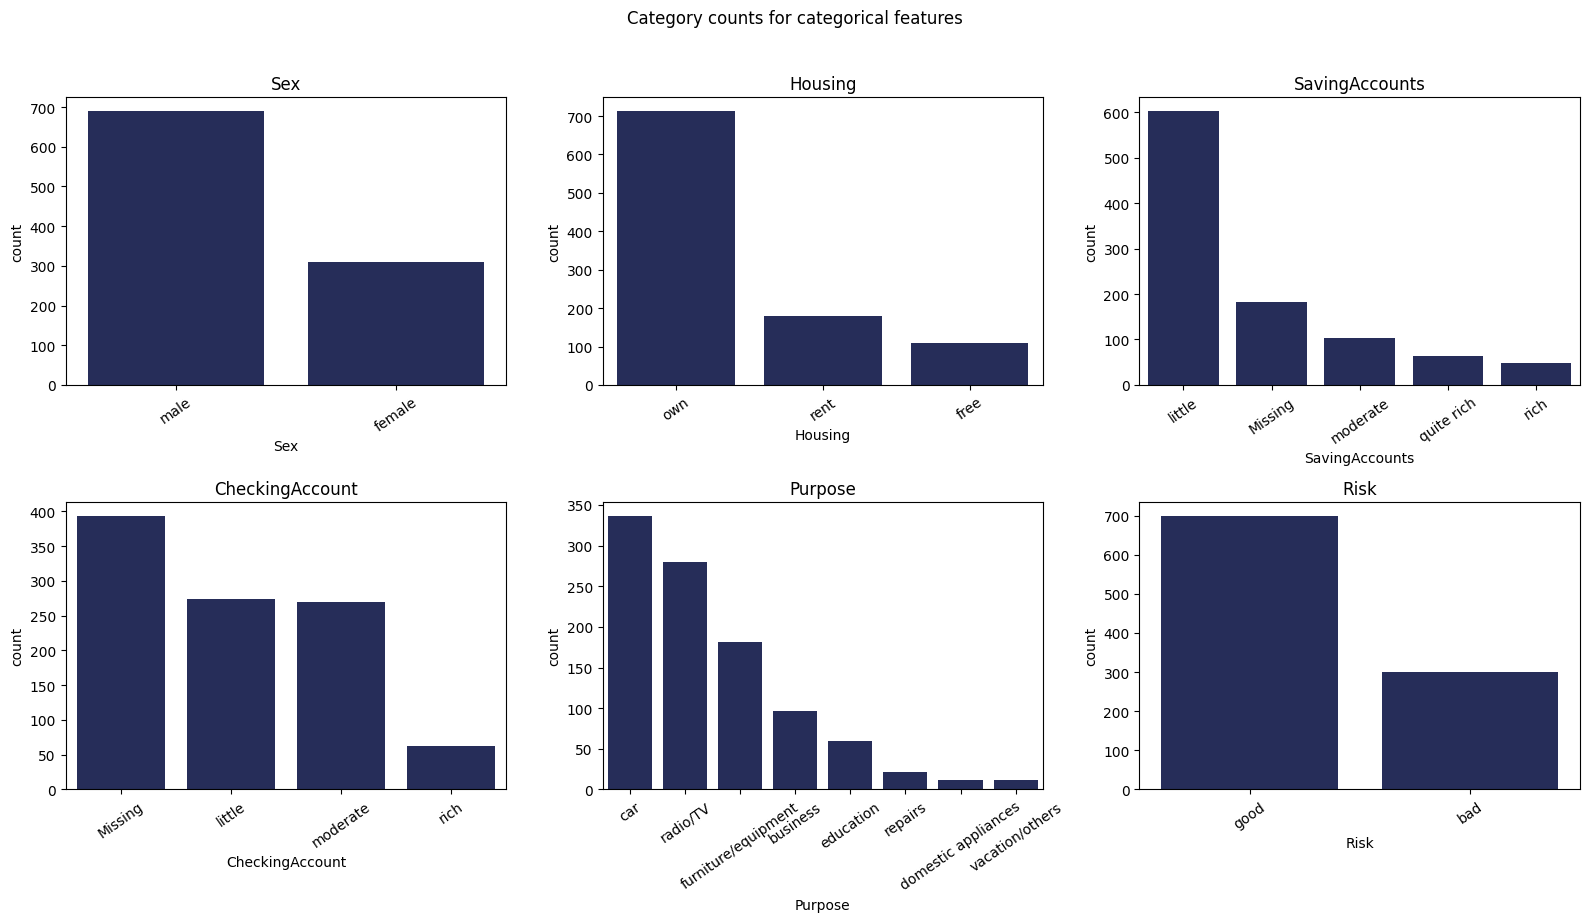

In [ ]:
ax.set_title(col)# I selected the categorical columns I want to explore.
categorical_cols = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

# I created six plots arranged in two rows and three columns.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# I arranged the plots in a single list to make them easier to use in the loop.
axes = axes.flatten()

# I created a count plot for each categorical column.
for ax, col in zip(axes, categorical_cols):
    # I replaced missing values with "Missing" so they appear in the chart.
    col_data = dataset[col].fillna("Missing")

    # I sorted the categories from most common to least common.
    order = col_data.value_counts().index

    # I created a bar chart showing the count of each category.
    sns.countplot(x=col_data, order=order, ax=ax, color="#1E2761")

    # I added the column name as the plot title.
    ax.set_title(col)

    # I rotated the category labels to make them easier to read.
    ax.tick_params(axis="x", rotation=35)

# I added a main title for all the plots.
plt.suptitle("Category counts for categorical features", y=1.02)

# I adjusted the layout to make the plots fit clearly.
plt.tight_layout()

# I displayed all the plots.
plt.show()


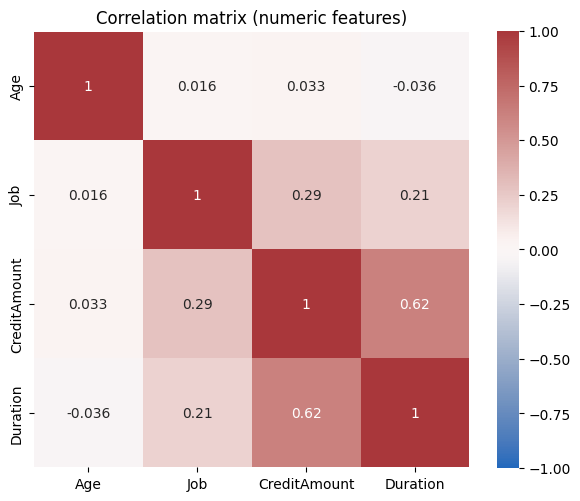

In [ ]:
# I set the size of the figure.
plt.figure(figsize=(6, 5))

# I calculated the correlation between the numerical columns.
correlation = dataset[numeric_cols].corr()

# I created a heatmap to show the correlation values using colors and numbers.
sns.heatmap(correlation, vmin=-1, vmax=1, annot=True, cmap="vlag", square=True)

# I added a title to the heatmap.
plt.title("Correlation matrix (numeric features)")

# I adjusted the layout to make the chart fit clearly.
plt.tight_layout()

# I displayed the heatmap.
plt.show()

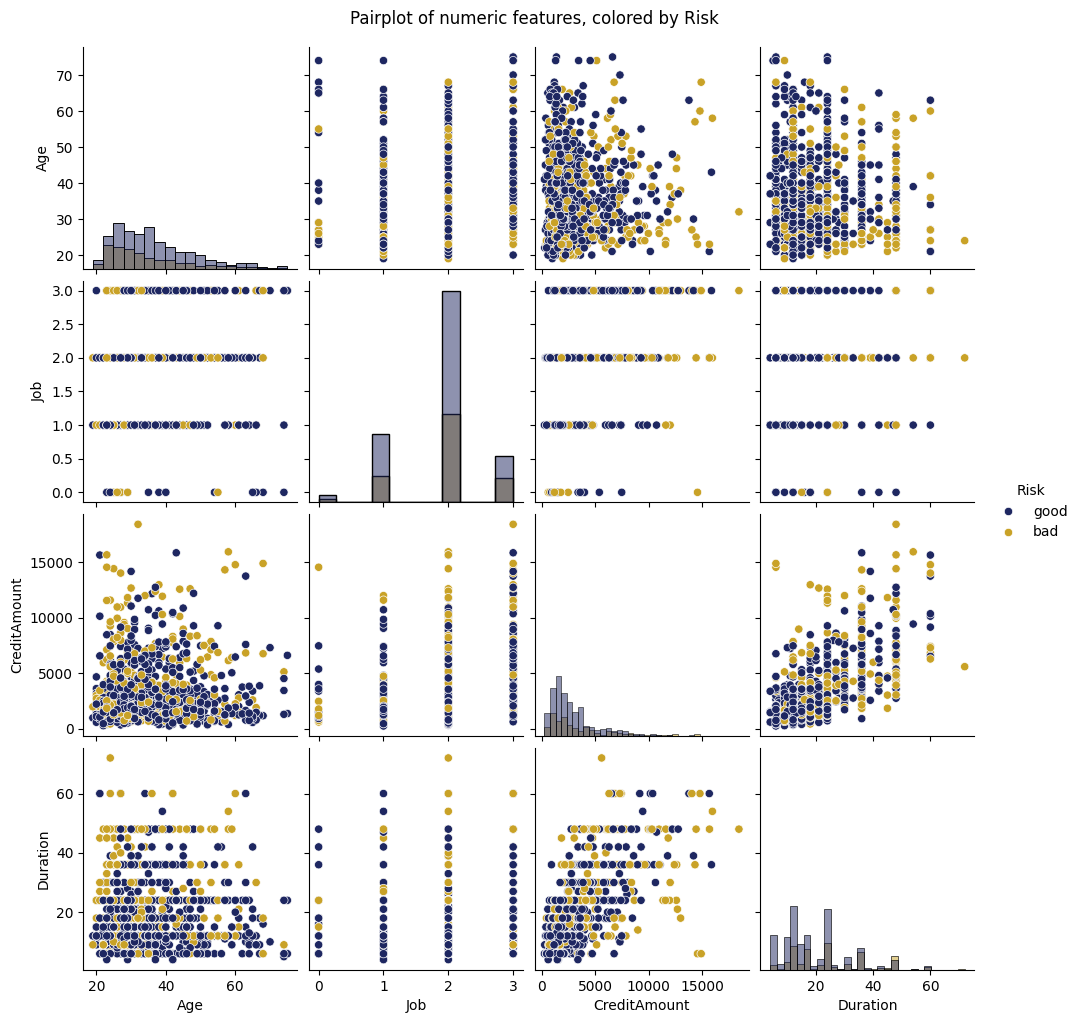

In [ ]:
# A pairplot ("scatterplot matrix") plots every numeric feature against every
# other one, colored by Risk -- a fast way to see whether good/bad risk cases
# separate visually along any pair of features.
sns.pairplot(dataset, vars=numeric_cols, hue="Risk", palette={"good": "#1E2761", "bad": "#C9A227"}, diag_kind="hist")
plt.suptitle("Pairplot of numeric features, colored by Risk", y=1.02)
plt.show()

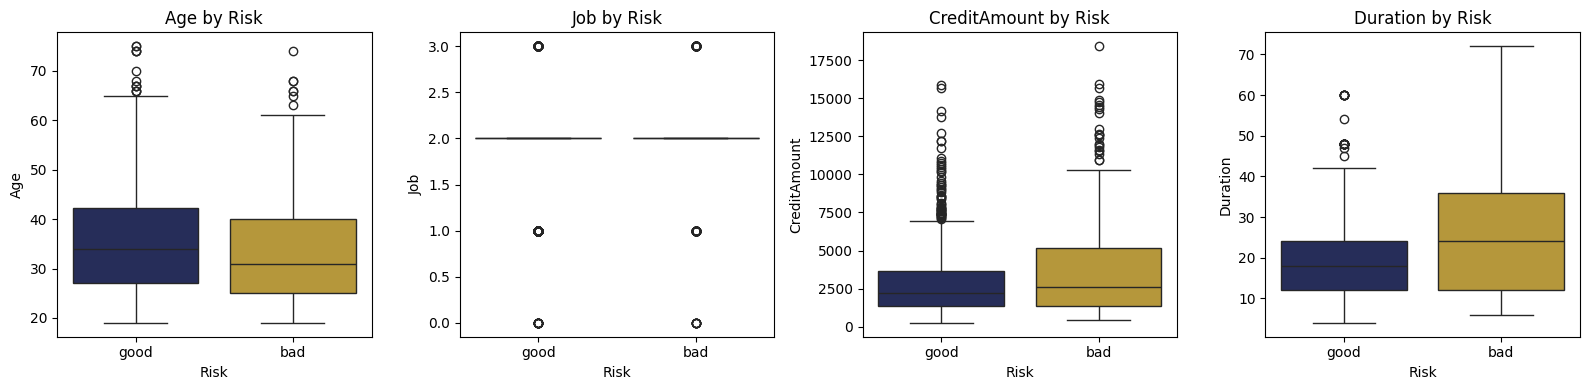

In [ ]:
# I created a separate plot for each numerical feature.
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(16, 4))

# I compared each numerical feature between the two Risk groups.
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(
        data=dataset,
        x="Risk",
        y=col,
        hue="Risk",
        palette={"good": "#1E2761", "bad": "#C9A227"},
        legend=False,
        ax=ax
    )

    # I added a title to each plot.
    ax.set_title(f"{col} by Risk")

# I adjusted the layout to make the plots fit clearly.
plt.tight_layout()

# I displayed the plots.
plt.show()

# I observed that bad-risk applicants may have higher credit amounts and durations.
# This could suggest a relationship between loan size, loan duration, and credit risk.


  ## Data Preparation

In [ ]:
# I created a copy of the original dataset to keep the raw data unchanged.
df_clean = dataset.copy()

# I replaced missing values in SavingAccounts with "none".
df_clean["SavingAccounts"] = df_clean["SavingAccounts"].fillna("none")

# I replaced missing values in CheckingAccount with "none".
df_clean["CheckingAccount"] = df_clean["CheckingAccount"].fillna("none")

# I checked whether any missing values remain in the cleaned dataset.
print("Remaining missing values:\n")
print(df_clean.isna().sum())


Remaining missing values:

Age                0
Sex                0
Job                0
Housing            0
SavingAccounts     0
CheckingAccount    0
CreditAmount       0
Duration           0
Purpose            0
Risk               0
dtype: int64


 ## Data transformation — encoding & scaling

In [ ]:
# I created a copy of the cleaned dataset for encoding.
df_encoded = df_clean.copy()

# I selected the categorical columns that I want to convert into numbers.
categorical_cols_all = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

# I created an empty dictionary to store the encoders.
encoders = {}

# I converted each categorical column into numerical codes.
for col in categorical_cols_all:
    # I created a LabelEncoder for the current column.
    le = LabelEncoder()

    # I learned the categories and replaced them with integer codes.
    df_encoded[col] = le.fit_transform(df_clean[col])

    # I saved the encoder so I can identify the original categories later.
    encoders[col] = le

    # I displayed the categories in the order used by the encoder.
    print(f"{col:16s} -> {list(le.classes_)}")


Sex              -> ['female', 'male']
Housing          -> ['free', 'own', 'rent']
SavingAccounts   -> ['little', 'moderate', 'none', 'quite rich', 'rich']
CheckingAccount  -> ['little', 'moderate', 'none', 'rich']
Purpose          -> ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/TV', 'repairs', 'vacation/others']
Risk             -> ['bad', 'good']


In [ ]:
# I created a StandardScaler to standardize the numerical columns.
scaler = StandardScaler()

# I selected the numerical columns I want to scale.
numeric_cols_to_scale = ["Age", "Job", "CreditAmount", "Duration"]

# I created a copy of the encoded dataset.
df_scaled = df_encoded.copy()

# I scaled the selected columns using their mean and standard deviation.
df_scaled[numeric_cols_to_scale] = scaler.fit_transform(df_encoded[numeric_cols_to_scale])

# I displayed the first three rows before scaling.
print("Before scaling:")
print(df_encoded[numeric_cols_to_scale].head(3))

# I displayed the first three rows after scaling, rounded to three decimal places.
print("\nAfter scaling (mean ~0, std ~1):")
print(df_scaled[numeric_cols_to_scale].head(3).round(3))

Before scaling:
   Age  Job  CreditAmount  Duration
0   67    2          1169         6
1   22    2          5951        48
2   49    1          2096        12

After scaling (mean ~0, std ~1):
     Age    Job  CreditAmount  Duration
0  2.766  0.147        -0.745    -1.236
1 -1.191  0.147         0.950     2.248
2  1.183 -1.384        -0.417    -0.739


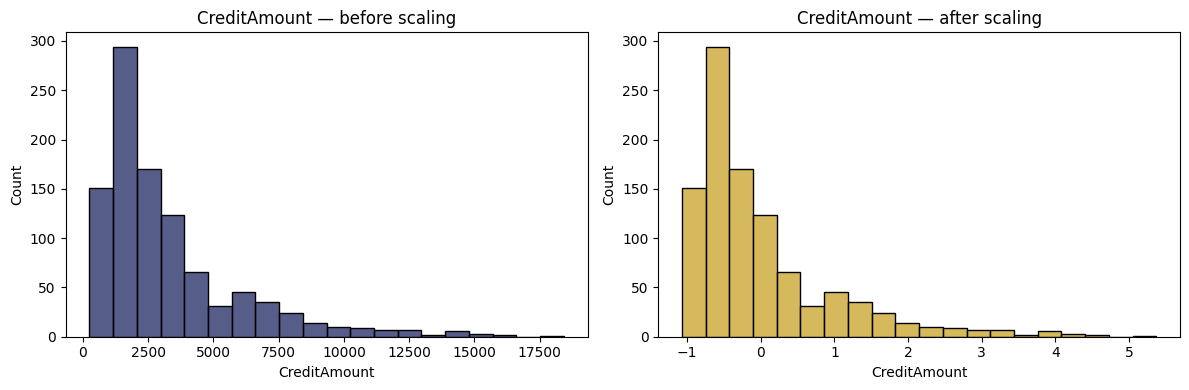

In [ ]:
# I created two plots next to each other.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# I drew the CreditAmount distribution before scaling.
sns.histplot(df_encoded["CreditAmount"], bins=20, ax=axes[0], color="#1E2761")
axes[0].set_title("CreditAmount — before scaling")

# I drew the CreditAmount distribution after scaling.
sns.histplot(df_scaled["CreditAmount"], bins=20, ax=axes[1], color="#C9A227")
axes[1].set_title("CreditAmount — after scaling")

# I adjusted the spacing between the plots.
plt.tight_layout()

# I displayed both plots.
plt.show()

## Feature selection

In [ ]:
# I separated the features (X) from the target column (y).
X = df_scaled.drop(columns=["Risk"])
y = df_scaled["Risk"]

# I created a tool to score all features using the ANOVA F-test.
selector = SelectKBest(score_func=f_classif, k="all")

# I fitted the selector using the features and the target.
selector.fit(X, y)

# I created a table with feature names and their scores.
feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
})

# I sorted the features from the highest score to the lowest.
feature_scores = feature_scores.sort_values(
    "Score", ascending=False
).reset_index(drop=True)

# I displayed the feature scores.
feature_scores


,Feature,Score
0,CheckingAccount,111.721482
1,Duration,48.333790
2,SavingAccounts,33.948465
3,CreditAmount,24.482366
4,Age,8.356995
5,Sex,5.720350
6,Purpose,3.745234
7,Job,1.070584
8,Housing,0.372463


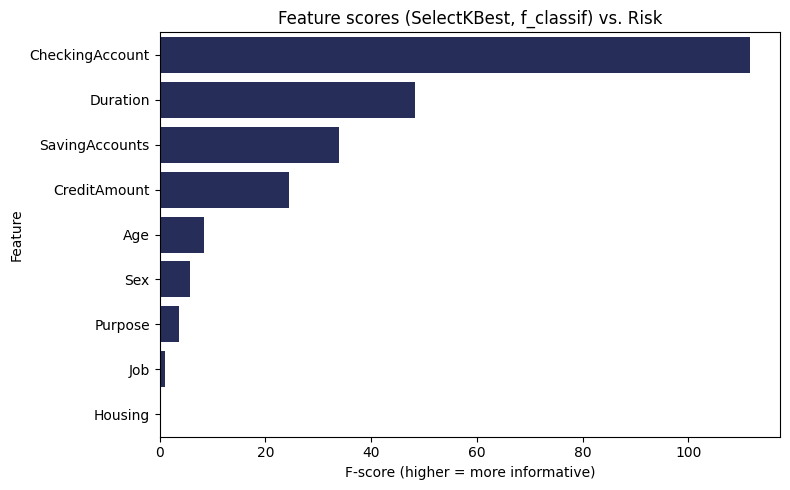

In [ ]:
# I created a figure for the feature scores chart.
plt.figure(figsize=(8, 5))

# I drew a bar chart to compare the feature scores.
sns.barplot(data=feature_scores, x="Score", y="Feature", color="#1E2761")

# I added a title to the chart.
plt.title("Feature scores (SelectKBest, f_classif) vs. Risk")

# I added a label to the x-axis.
plt.xlabel("F-score (higher = more informative)")

# I adjusted the spacing in the chart.
plt.tight_layout()

# I displayed the chart.
plt.show()

# I used this ranking to understand which features may be useful for modeling.
# This step does not train a model or make predictions.
